# Assignment 1, Predictive Methods - AVTEK 2025 

Participants names and contributions
Daniel Mononen
Carita Kuusisto
Annastiina Hintsala

## Part 1

### 1.1 Dataset from Kaggle

Valittiin kaglesta rintasyöpään liittyvä datasetti. 
https://www.kaggle.com/datasets/erdemtaha/cancer-data

Datasetti sisältää id:n potilaalle sekä y arvona diagnoosin (B/M) ja kuvaavina arvoina (x) 17 eri visuaalista arvoa syövästä. 



### Ladataan datasetti dataframeen



In [1]:
#Otetaan tarvittavat kirjastot käyttöön

import pandas as pd
import numpy as np
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


data = pd.read_csv('Cancer_Data.csv') 
data.info() # general information of the data
print(data["Unnamed: 32"]) # a column that is completely null
print(data["id"]) # an unnecessary value for the algorithm
data.tail()
data.isnull().sum()
data.drop(columns='Unnamed: 32',inplace=True) # pudotetaan tarpeeton sarake


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

### Luodaan taulukko jossa kuvaavat arvot sekä diagnoosi sarake Y:ssä

In [2]:
# kNN-analyysi
# Määritellään X ja y
x = data.iloc[:, 2:12]  # kuvaavat arvot, sarakkeet 2-11
y = data['diagnosis']    # y-arvo, tietty sarake

k = 5  # määritellään k:n arvo




In [3]:
x = data.iloc[:, 2:12]  # kuvaavat arvot, sarakkeet 2-11, kaikki keskiarvot
x

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883
...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016


In [4]:
y = data['diagnosis'] 
y

0      M
1      M
2      M
3      M
4      M
      ..
564    M
565    M
566    M
567    M
568    B
Name: diagnosis, Length: 569, dtype: object

### 1.2 First kNN run (Training) 


In [5]:
x_train, x_test, y_train, y_test= train_test_split(x, y, test_size = 0.2, shuffle = True, random_state = 0)

### 1.2 First kNN run (Testing)

In [6]:
K=3
knn=KNeighborsClassifier(K)
knn.fit(x_train, y_train)
y_pred_sklearn= knn.predict(x_test)

print("Ennusteiden määrä:", len(y_pred_sklearn))
print("Ennusteet:", y_pred_sklearn)


print("Mallin tarkkuus:",accuracy_score(y_test, y_pred_sklearn))

Ennusteiden määrä: 114
Ennusteet: ['B' 'B' 'B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'M' 'B' 'B' 'B' 'M'
 'M' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'M' 'B' 'M' 'B' 'M' 'B' 'M' 'B' 'B'
 'B' 'M' 'B' 'M' 'M' 'B' 'B' 'B' 'B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'M' 'B'
 'B' 'B' 'B' 'B' 'B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'M' 'M' 'M' 'B' 'B' 'B'
 'B' 'B' 'M' 'B' 'B' 'B' 'B' 'B' 'M' 'M' 'M' 'B' 'B' 'B' 'B' 'B' 'M' 'M'
 'B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'M' 'M' 'B' 'M' 'B'
 'M' 'M' 'B' 'M' 'M' 'B']
Mallin tarkkuus: 0.868421052631579


### 1.3 Listing of 2 more interresting use cases for kNN algorithm

1. Diabeteksen ennustaminen
    Algoritmi vertailee uuden potilaan mittaustietoja kuten verensokeria, painoindeksiä ja ikää aineistossa olevien muiden potilaiden tietoihin. Samankaltaisten potilaiden diagnoosien perusteella algoritmi ennustaa, kuuluuko uusi potilas diabetesluokkaan vai ei.

2. Asiakkaiden ostoskäyttäytymisen ennustaminen
    Verkkokauppa voi hyödyntää kNN- algoritmia asiakkaiden ostoskäyttäytymisen ennustamisessa. Algoritmi vertailee asiakkaiden ostohistoriaa ja muita ominaisuuksia samankaltaisten asiakkaiden tietoihin. Näin voidaan esimerkiksi ennustaa, onko asiakas kiinnostunut tietystä tuoteryhmästä. 

## Part 2

### 2.1 Experiments with different values of $k$

In [7]:
K = 3
knn = KNeighborsClassifier(K)
knn.fit(x_train, y_train)
y_pred_sklearn = knn.predict(x_test)

print("K-arvo:", K)
print("Mallin tarkkuus:", accuracy_score(y_test, y_pred_sklearn))


K-arvo: 3
Mallin tarkkuus: 0.868421052631579


Tässä tehtävässä kokeilimme kNN- algoritmia eri k-arvoilla ja vertailimme niiden vaikutusta mallin tarkkuuteen. Opetusaineiston osuus oli 80 % ja testiaineiston 20%. Testasimme k-arvoja 3, 5, 7, 9 ja 11.
Tuloksena tuli:

k-arvo          Mallin tarkkuus
3               86,84 %
5               91,23 %
7               90,35 %
9               89,47 %
11              87,72 %

Paras tarkkuus saatiin k-arvolla 5, jolloin mallin tarkkuus oli 91,23 %. K-arvolla 3 tarkkuus oli 86,84 %. Tarkkuus parani, kun k-arvo nostettiin viiteen. Tätä suuremmalla k-arvolla tarkkuus alkoi vähitellen laskea.

Testataan vielä foor-silmukalla k-arvot 1-30. Paras tarkkuus oli 92,11 %, joka saavutettiin useilla eri k-arvoilla, esimerkiksi arvoilla 12, 14 ja 20. Huomasimme, ettei tarkkuus parane tasaisesti k-arvon kasvaessa. Useat eri k-arvot voivat myös tuottaa saman tarkkuuden.Kokeilun perusteella k-arvon valinnalla on vaikutusta mallin toimintaan, mutta suurempi k-arvo ei automaattisesti tarkoita parempaa tulosta. Lopuksi tehdään graafinen esitys k-arvon muutoksista.

In [10]:
import matplotlib.pyplot as plt

k_arvot = []
tarkkuudet = []

for K in range(1, 31):
    knn = KNeighborsClassifier(K)
    knn.fit(x_train, y_train)
    y_pred = knn.predict(x_test)

    tarkkuus = accuracy_score(y_test, y_pred)

    k_arvot.append(K)
    tarkkuudet.append(tarkkuus * 100)

    print("K-arvo:", K, "Tarkkuus:", round(tarkkuus * 100, 2), "%")

K-arvo: 1 Tarkkuus: 85.96 %
K-arvo: 2 Tarkkuus: 83.33 %
K-arvo: 3 Tarkkuus: 86.84 %
K-arvo: 4 Tarkkuus: 88.6 %
K-arvo: 5 Tarkkuus: 91.23 %
K-arvo: 6 Tarkkuus: 91.23 %
K-arvo: 7 Tarkkuus: 90.35 %
K-arvo: 8 Tarkkuus: 90.35 %
K-arvo: 9 Tarkkuus: 89.47 %
K-arvo: 10 Tarkkuus: 90.35 %
K-arvo: 11 Tarkkuus: 87.72 %
K-arvo: 12 Tarkkuus: 92.11 %
K-arvo: 13 Tarkkuus: 91.23 %
K-arvo: 14 Tarkkuus: 92.11 %
K-arvo: 15 Tarkkuus: 91.23 %
K-arvo: 16 Tarkkuus: 91.23 %
K-arvo: 17 Tarkkuus: 91.23 %
K-arvo: 18 Tarkkuus: 91.23 %
K-arvo: 19 Tarkkuus: 91.23 %
K-arvo: 20 Tarkkuus: 92.11 %
K-arvo: 21 Tarkkuus: 91.23 %
K-arvo: 22 Tarkkuus: 91.23 %
K-arvo: 23 Tarkkuus: 91.23 %
K-arvo: 24 Tarkkuus: 92.11 %
K-arvo: 25 Tarkkuus: 92.11 %
K-arvo: 26 Tarkkuus: 92.11 %
K-arvo: 27 Tarkkuus: 92.11 %
K-arvo: 28 Tarkkuus: 92.11 %
K-arvo: 29 Tarkkuus: 92.11 %
K-arvo: 30 Tarkkuus: 92.11 %


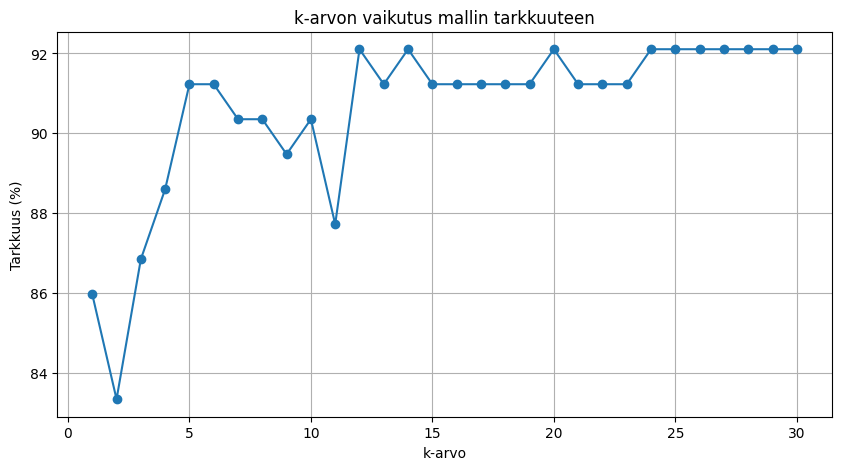

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(k_arvot, tarkkuudet, marker='o')

plt.title("k-arvon vaikutus mallin tarkkuuteen")
plt.xlabel("k-arvo")
plt.ylabel("Tarkkuus (%)")

plt.grid(True)
plt.show()


### 2.2 Studying the effect of different train/test splits

### 2.3 $k$-fold validation